# The first-quarter lead and the rest of the Finals

Joseph Smarrelli · September 2026

This notebook recalculates selected findings from the included derived tables. It does not refit the underlying models. See the repository README for the complete source-data build and the accompanying article for interpretation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import json
from IPython.display import display, Image
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
p = root / 'projects' / '08_finals_postmortem_R'

## Recalculate the result
The assertions check that the article’s reported quantities agree with the delivered tables.

In [2]:
games = pd.read_csv(p / 'game_summary.csv')
quarters = pd.read_csv(p / 'quarter_summary.csv')
assert games.spurs_points.sum() == quarters.spurs_points.sum()
assert games.opp_points.sum() == quarters.opp_points.sum()
resamples = pd.read_csv(p / 'series_resample.csv')
assert np.isclose(resamples.probability.sum(), 1)
display(pd.Series({'Spurs_points': games.spurs_points.sum(), 'opponent_points': games.opp_points.sum(), 'margin': games.spurs_points.sum() - games.opp_points.sum()}))
display(quarters)

Spurs_points       510
opponent_points    522
margin             -12
dtype: int64

,period,spurs_points,opp_points,team_possessions,margin,net_rating
0,1,158,101,119.0,57,47.899160
1,2,124,153,126.5,-29,-22.924901
2,3,123,137,117.0,-14,-11.965812
3,4,105,131,116.0,-26,-22.413793


## Inspect the estimates

In [3]:
display(games)
display(resamples)

,game_number,spurs_points,opp_points,team_possessions,seconds,margin,off_rating,def_rating,net_rating,result
0,1,95,105,98.5,2880,-10,96.446701,106.598985,-10.152284,L
1,2,104,105,98.5,2880,-1,105.583756,106.598985,-1.015228,L
2,3,115,111,94.0,2880,4,122.340426,118.085106,4.255319,W
3,4,106,107,94.0,2880,-1,112.765957,113.829787,-1.063830,L
4,5,90,94,93.5,2880,-4,96.256684,100.534759,-4.278075,L


,spurs_wins,probability
0,0,0.04870
1,1,0.20735
2,2,0.34535
3,3,0.27430
4,4,0.10860
5,5,0.01570


## Figures

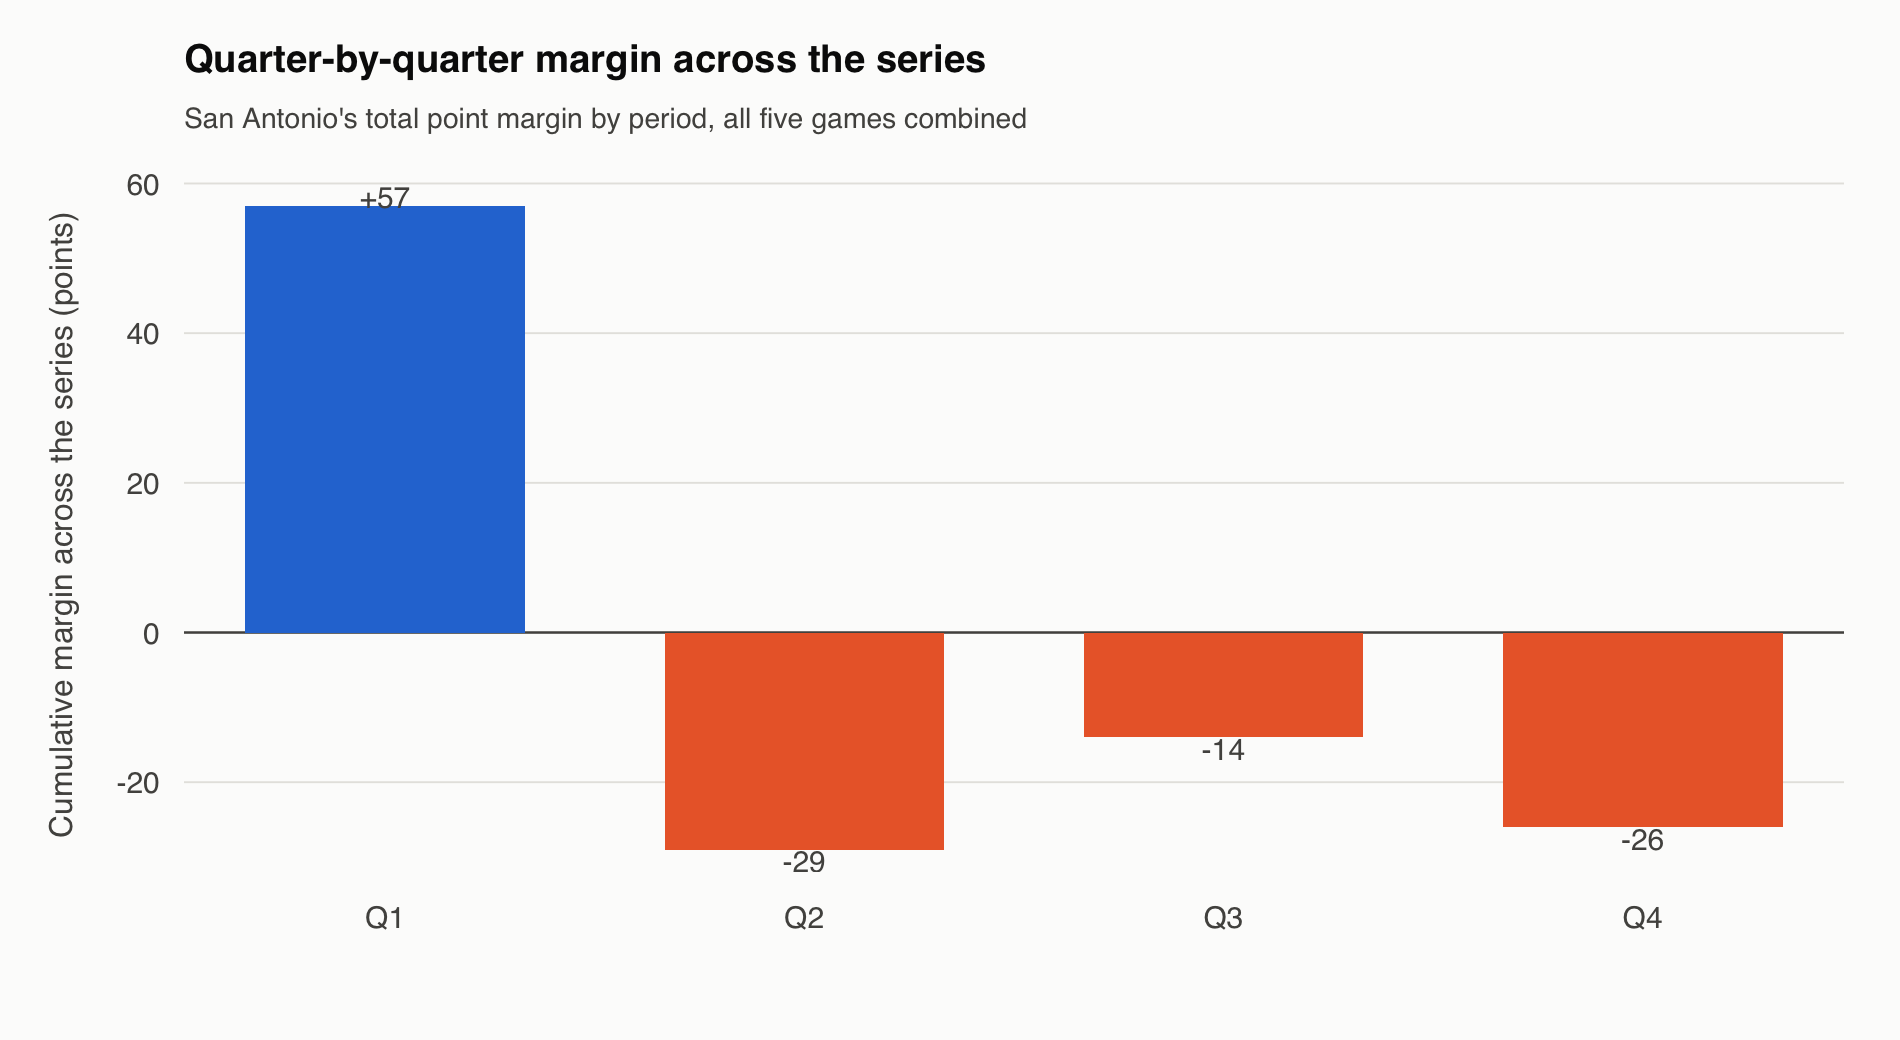

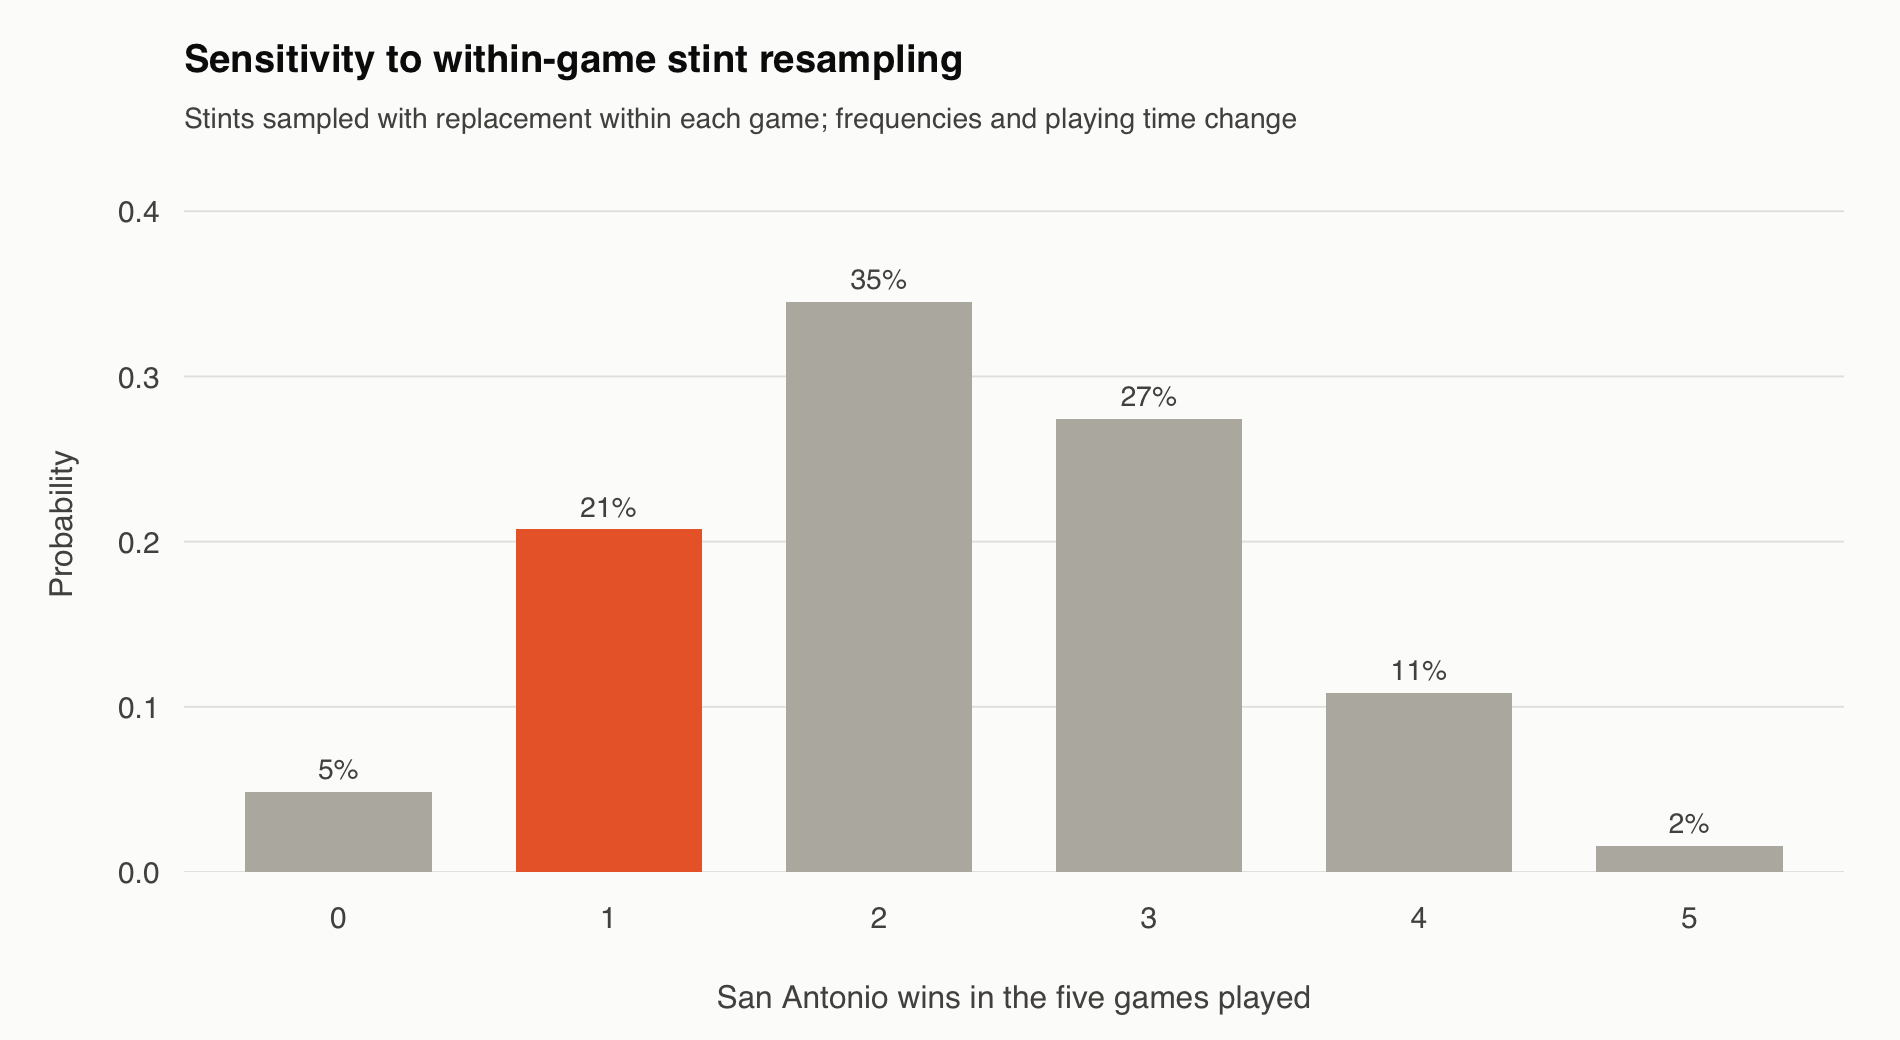

In [4]:
display(Image(filename=str(root / 'projects/08_finals_postmortem_R/figures/quarter_margins.png')))
display(Image(filename=str(root / 'projects/08_finals_postmortem_R/figures/series_resample.png')))

## Interpretation limits
Resampling observed stints with replacement changes their frequency, playing time and composition. It does not estimate a seven-game series win probability or certify lineup identities in the Finals games.